In [10]:
!pip install pandas numpy matplotlib seaborn openpyxl scikit-learn

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
data = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [13]:
print(data.shape)
data.info()
display(data.head())

(7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [14]:
data = data.drop('customerID',axis=1)

In [15]:
data['TotalCharges']=pd.to_numeric(data['TotalCharges'],errors='coerce')

In [16]:
print(data.isnull().sum())
data= data.dropna()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


Churn
No     5163
Yes    1869
Name: count, dtype: int64


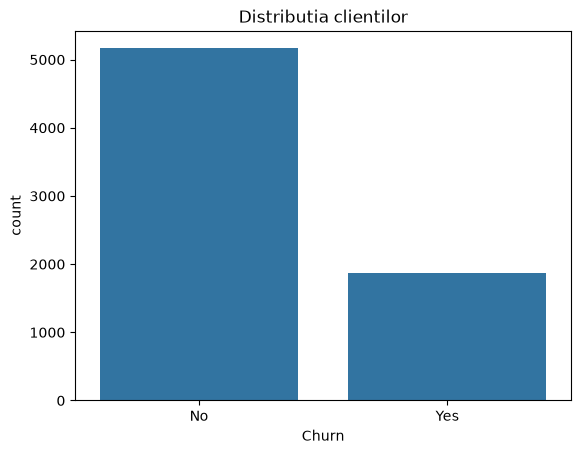

In [17]:
print(data['Churn'].value_counts())
sns.countplot(data=data,x='Churn')
plt.title("Distributia clientilor")
plt.show()

In [18]:
data.isnull().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

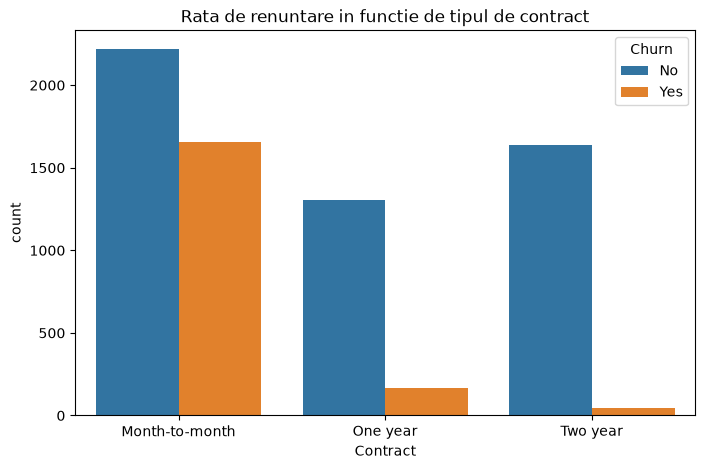

In [19]:
plt.figure(figsize=(8,5))
sns.countplot(data=data,x='Contract',hue='Churn')
plt.title("Rata de renuntare in functie de tipul de contract")
plt.show()

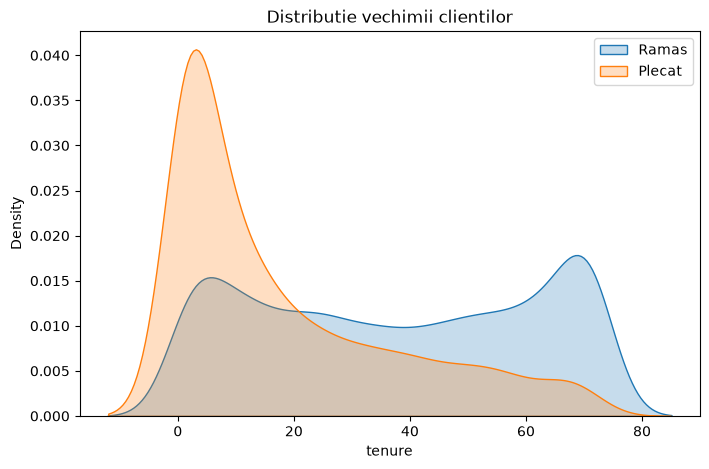

In [20]:
plt.figure(figsize=(8,5))
sns.kdeplot(data=data[data['Churn']=='No'], x='tenure',label='Ramas',fill=True)
sns.kdeplot(data=data[data['Churn']=='Yes'],x='tenure',label='Plecat',fill=True)
plt.title("Distributie vechimii clientilor")
plt.legend()
plt.show()

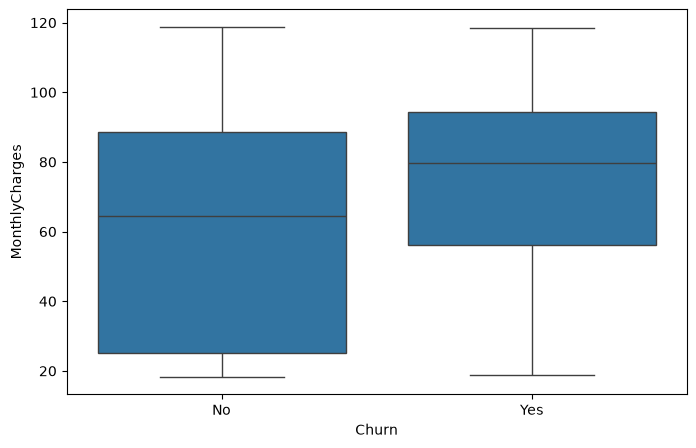

In [21]:
plt.figure(figsize=(8,5))
sns.boxplot(data=data,x='Churn',y='MonthlyCharges')
plt.show()

In [22]:
display(data.head())

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [23]:
print(data['PhoneService'].unique())
print(data['OnlineSecurity'].unique())
print(data['OnlineBackup'].unique())
print(data['DeviceProtection'].unique())
print(data['TechSupport'].unique())
print(data['StreamingTV'].unique())
print(data['StreamingMovies'].unique())
print(data['PaperlessBilling'].unique())

<StringArray>
['No', 'Yes']
Length: 2, dtype: str
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
<StringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
<StringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
<StringArray>
['Yes', 'No']
Length: 2, dtype: str


In [24]:
data['gender']=data['gender'].map({'Female':0,'Male':1})
coloane = ['Partner','Dependents','PhoneService','PaperlessBilling','Churn']
for col in coloane:
    data[col]=data[col].map({'No':0,'Yes':1})

In [25]:
data = pd.get_dummies(data,drop_first=True,dtype=int)
print(data.shape)
display(data.head())

(7032, 31)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,0,0,0,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,0,0,0,0,0,0,0,0,1,0


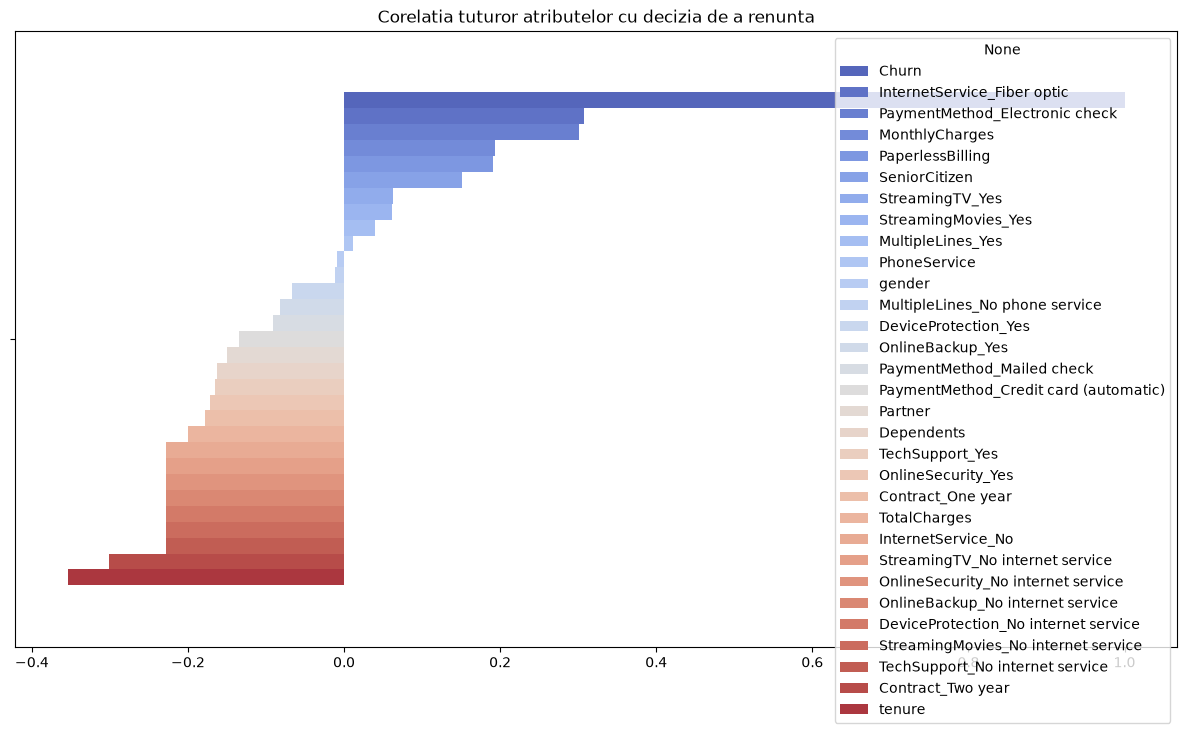

In [26]:
plt.figure(figsize=(15,8))
corr = data.corr()['Churn'].sort_values(ascending=False)
#print(corr)
sns.barplot(x=corr.values,hue=corr.index,palette='coolwarm')
plt.title('Corelatia tuturor atributelor cu decizia de a renunta')
plt.show()

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

x = data.drop('Churn',axis=1)
y = data['Churn'].values

In [28]:
xTrain, xTest, yTrain, yTest = train_test_split(x,y,test_size=0.20,random_state=40)
scaler = StandardScaler()
xTrainScaled = scaler.fit_transform(xTrain)
xTestScaled = scaler.transform(xTest)

model = LogisticRegression()
model.fit(xTrainScaled,yTrain)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

              precision    recall  f1-score   support

           0       0.86      0.88      0.87      1050
           1       0.61      0.57      0.59       357

    accuracy                           0.80      1407
   macro avg       0.73      0.72      0.73      1407
weighted avg       0.79      0.80      0.80      1407



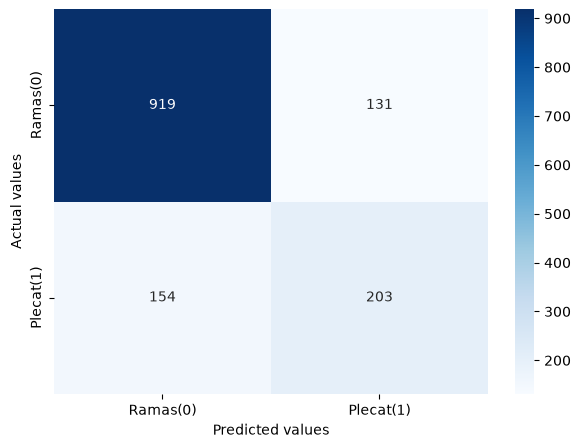

In [29]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

yPred = model.predict(xTestScaled)

acc = accuracy_score(yTest,yPred)

print(classification_report(yTest,yPred))

cm = confusion_matrix(yTest,yPred)
plt.figure(figsize=(7,5))

sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',xticklabels=['Ramas(0)','Plecat(1)'],yticklabels=['Ramas(0)','Plecat(1)'])
plt.xlabel("Predicted values")
plt.ylabel("Actual values")
plt.show()

/home/curgiu/Documents/Facultate/customer/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2823: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


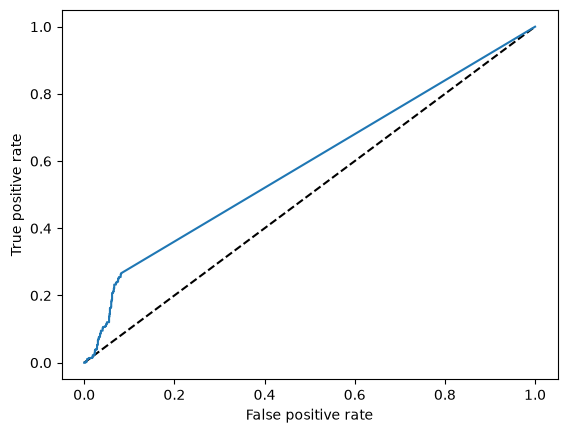

In [30]:
from sklearn.metrics import roc_curve, roc_auc_score

PredProb = model.predict_proba(xTest)[:,0]
fpr, tpr, thresholds = roc_curve(yTest,PredProb,pos_label=1)
plt.plot([0,1],[0,1],'k--')
plt.plot(fpr,tpr)
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')

plt.show()

In [31]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(model,xTrainScaled,yTrain,cv=5,scoring='accuracy')

print("Scorurile a 5 teste: ",cv_scores)
print(f"Acuratetea medie: {cv_scores.mean()*100:.2f}%")
print(f"Varianta: {cv_scores.std()*100:.2f}%")

Scorurile a 5 teste:  [0.78933333 0.81866667 0.808      0.816      0.79822222]
Acuratetea medie: 80.60%
Varianta: 1.10%


/tmp/ipykernel_49095/2925245522.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feature_importance.head(10),x='Importanta',y='Attr',palette='coolwarm')


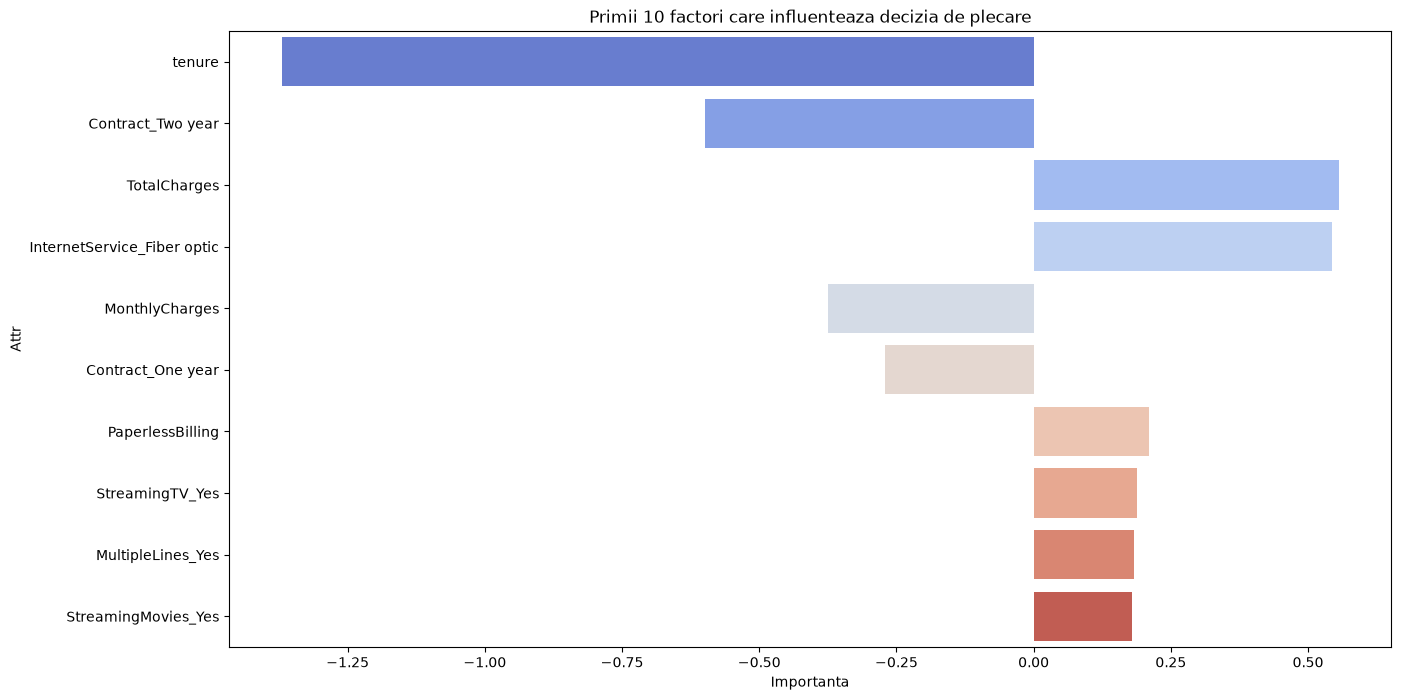

In [32]:
coef = model.coef_[0]
feature_importance = pd.DataFrame({
    'Attr':x.columns,
    'Importanta': coef
})
feature_importance['Importanta absoluta'] = feature_importance['Importanta'].abs()

feature_importance = feature_importance.sort_values(by='Importanta absoluta',ascending=False)

plt.figure(figsize=(15,8))
sns.barplot(data=feature_importance.head(10),x='Importanta',y='Attr',palette='coolwarm')
plt.title('Primii 10 factori care influenteaza decizia de plecare')
plt.show()

Model:  LogisticRegression()
Classification report:
              precision    recall  f1-score   support

           0       0.86      0.88      0.87      1050
           1       0.61      0.57      0.59       357

    accuracy                           0.80      1407
   macro avg       0.73      0.72      0.73      1407
weighted avg       0.79      0.80      0.80      1407



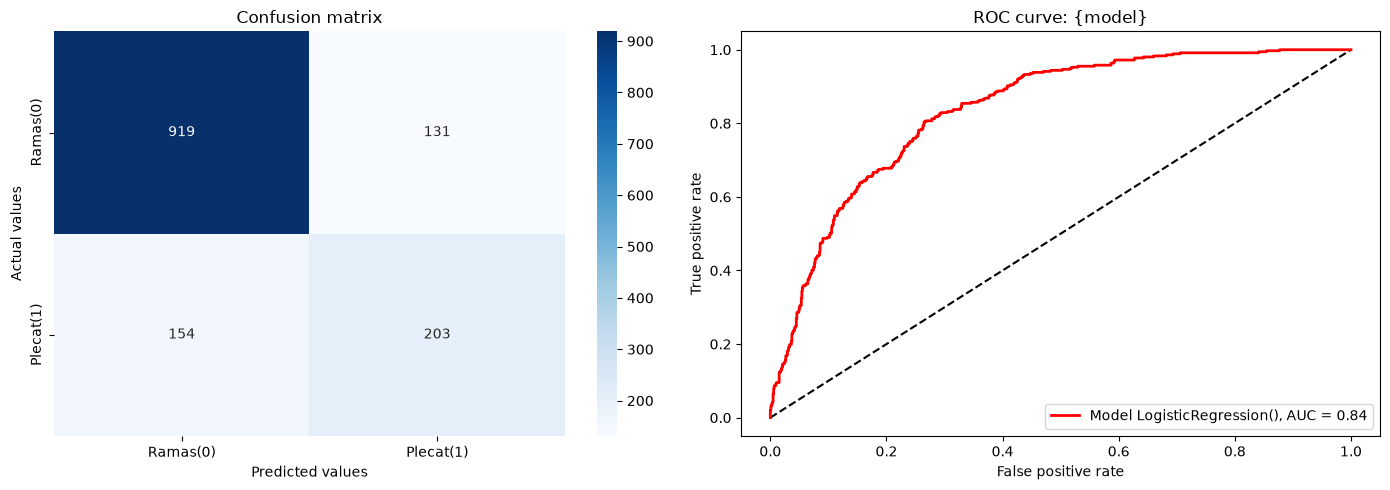



Model:  RandomForestClassifier(random_state=42)
Classification report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85      1050
           1       0.56      0.47      0.51       357

    accuracy                           0.77      1407
   macro avg       0.69      0.67      0.68      1407
weighted avg       0.76      0.77      0.76      1407



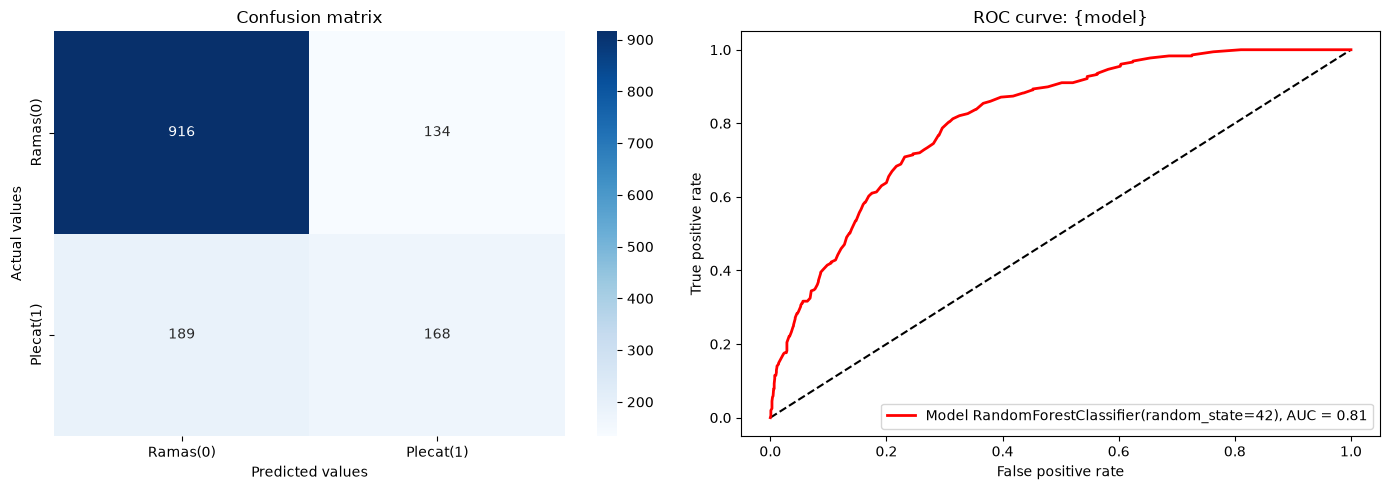



Model:  GradientBoostingClassifier(random_state=42)
Classification report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86      1050
           1       0.59      0.52      0.56       357

    accuracy                           0.79      1407
   macro avg       0.72      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407



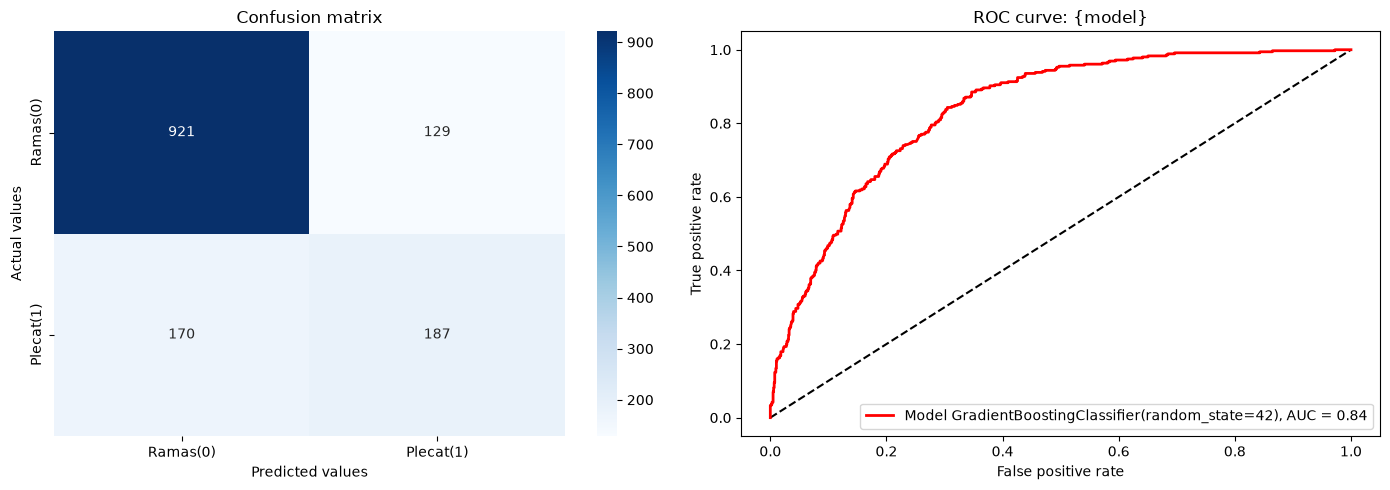

/home/curgiu/Documents/Facultate/customer/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Model:  SVC(probability=True, random_state=42)
Classification report:
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1050
           1       0.61      0.49      0.54       357

    accuracy                           0.79      1407
   macro avg       0.72      0.69      0.70      1407
weighted avg       0.78      0.79      0.78      1407



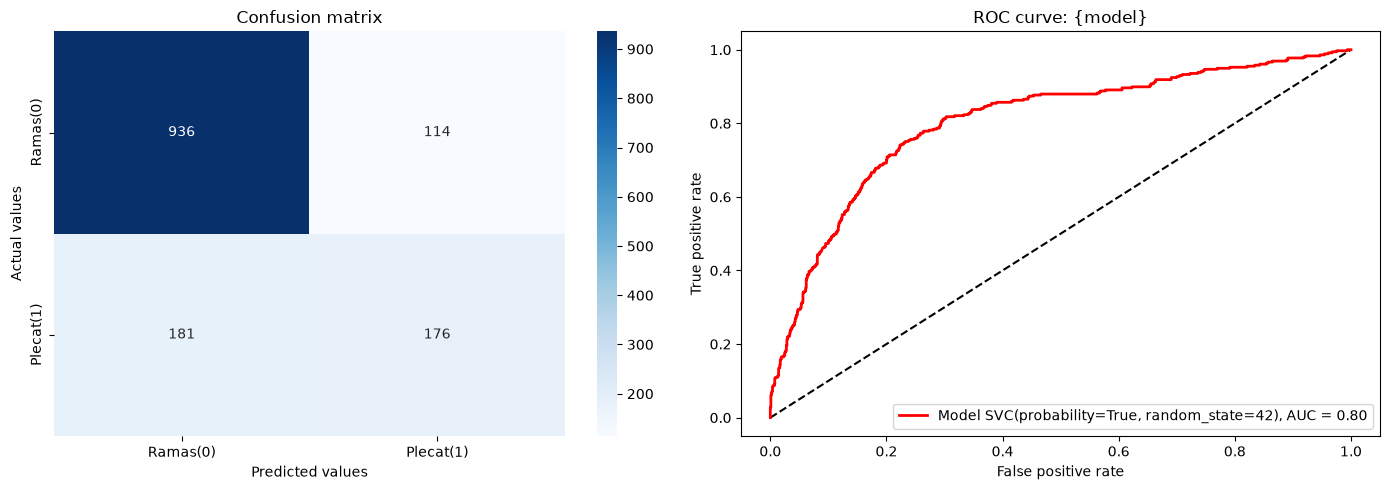



Model:  KNeighborsClassifier()
Classification report:
              precision    recall  f1-score   support

           0       0.83      0.83      0.83      1050
           1       0.51      0.51      0.51       357

    accuracy                           0.75      1407
   macro avg       0.67      0.67      0.67      1407
weighted avg       0.75      0.75      0.75      1407



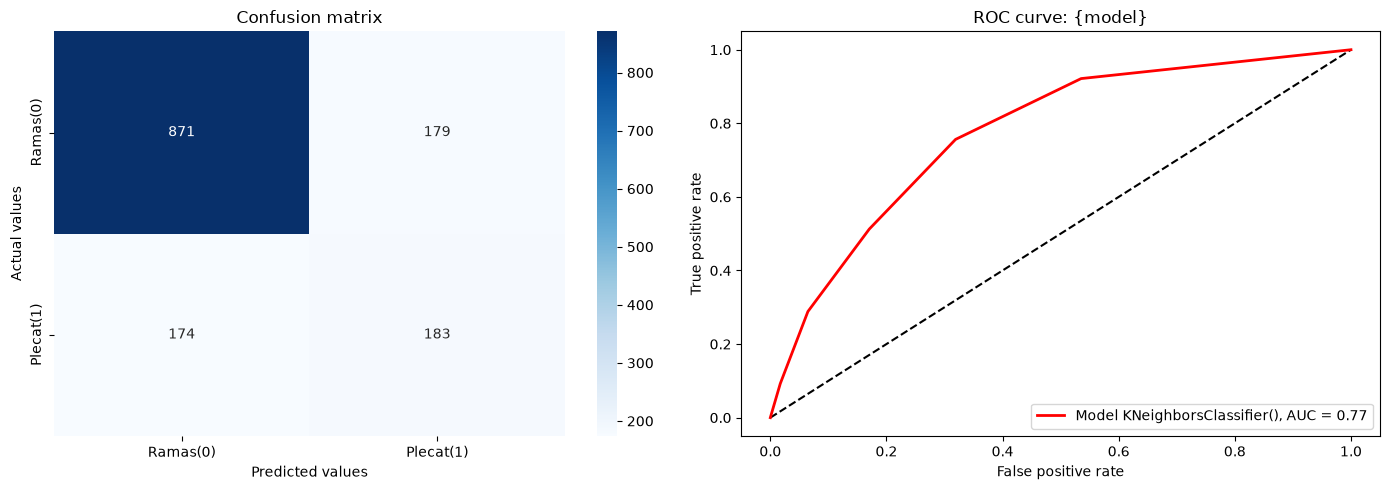

,Alg,Accuracy,ROC-AUC score
0,GradientBoosting,0.787491,0.837540
1,LogisticRegression,0.797441,0.836665
2,RandomForest,0.770434,0.814059
3,SVM,0.790334,0.803932
4,KNN,0.749112,0.774375


In [33]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

models = {
    "LogisticRegression":LogisticRegression(),
    "RandomForest": RandomForestClassifier(random_state=42),
    "GradientBoosting":GradientBoostingClassifier(random_state=42),
    "SVM":SVC(probability=True,random_state=42),
    "KNN": KNeighborsClassifier()
}

rez=[]

for name,model in models.items():
    model.fit(xTrainScaled,yTrain)
    yPred = model.predict(xTestScaled)
    yPredProba = model.predict_proba(xTestScaled)[:,1]

    acc = accuracy_score(yTest,yPred)
    auc = roc_auc_score(yTest,yPredProba)

    rez.append({"Alg":name,'Accuracy':acc,'ROC-AUC score':auc})
    print("Model: ",model)
    print("Classification report:")
    print(classification_report(yTest,yPred))
    fig,axes = plt.subplots(1,2,figsize=(14,5))
    cm = confusion_matrix(yTest,yPred)
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',
                xticklabels=['Ramas(0)','Plecat(1)'],
                yticklabels=['Ramas(0)','Plecat(1)'],
                ax=axes[0])
    axes[0].set_ylabel("Actual values")
    axes[0].set_xlabel("Predicted values")
    axes[0].set_title("Confusion matrix")

    fpr, tpr, thresholds = roc_curve(yTest,yPredProba)
    auc_score = roc_auc_score(yTest,yPredProba)

    axes[1].plot([0, 1],[0,1],'k--')
    axes[1].plot(fpr,tpr,color='red',linewidth=2,label=f'Model {model}, AUC = {auc_score:.2f}')
    axes[1].set_xlabel('False positive rate')
    axes[1].set_ylabel('True positive rate')
    axes[1].set_title('ROC curve: {model}')
    axes[1].legend(loc='lower right')

    plt.tight_layout()
    plt.show()
    print("\n")

rez_table = pd.DataFrame(rez)
rez_table = rez_table.sort_values(by='ROC-AUC score',ascending=False).reset_index(drop=True)
display(rez_table)